# HDBSCAN

HDBSCAN follows connected groups over a range of density levels. Short-lived groups can be labelled as noise.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Fit the grouping

The generator supplies reference labels for scoring. The estimator sees only the coordinates.

In [2]:
import matplotlib.pyplot as plt
from sklearn.cluster import HDBSCAN
from gallery.unsupervised import cluster_data, cluster_report

## Point cloud

In [3]:
X, reference = cluster_data("moons")
model = HDBSCAN(min_cluster_size=24, min_samples=7, copy=True)
labels = model.fit_predict(X)

## Group quality

External scores include every observation. Internal scores are calculated on assigned points.

Clusters: 2 | Assigned: 100.0% | Noise points: 0
Adjusted Rand index (all): 1.000
Adjusted mutual information (all): 1.000
Silhouette (assigned): 0.330
Davies–Bouldin (assigned): 1.166
Calinski–Harabasz (assigned): 355.6


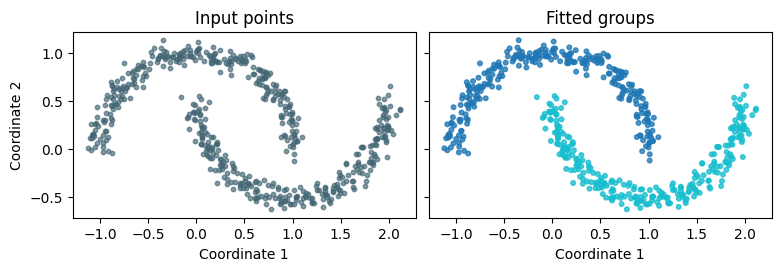

In [4]:
cluster_report(X, reference, labels)
plt.show()

## Reading the result

The adjusted Rand index compares fitted groups with the generating labels. The silhouette measures compactness, which can penalise a correctly recovered crescent or ring.

## References

[scikit-learn, HDBSCAN](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.HDBSCAN.html)

[scikit-learn, make_moons](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_moons.html)

[scikit-learn, clustering algorithms and evaluation](https://scikit-learn.org/stable/modules/clustering.html)

[Dataset generators and evaluation](../../../gallery/unsupervised.py)